<a href="https://colab.research.google.com/github/ahsan-zeb10/Models/blob/main/fer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import sys
import shutil
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [ ]:
print("="*60)
print("📂 MOUNTING GOOGLE DRIVE")
print("="*60)
if 'google.colab' in sys.modules:
    drive.mount('/content/drive')

# --- Define Paths ---
ZIP_PATH = "/content/drive/MyDrive/FER2013.zip"
EXTRACT_PATH = "/content/FER_CLEANED_DATA"
DRIVE_MODEL_PATH = '/content/drive/MyDrive/FER_Models'

print("="*60)
print("📦 EXTRACTING DATASET & DEFINING ROOT PATH")
print("="*60)

if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)
    print("🧹 Cleared previous extraction directory.")
os.makedirs(EXTRACT_PATH, exist_ok=True)

if os.path.exists(ZIP_PATH):
    try:
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            print(f"Unzipping {ZIP_PATH} to {EXTRACT_PATH}...")
            zip_ref.extractall(EXTRACT_PATH)
            print("✅ Extraction complete!")
    except Exception as e:
        print(f"❌ Error during extraction: {e}")
        raise
else:
    raise FileNotFoundError(f"❌ ERROR: ZIP file not found at: {ZIP_PATH}. Please check the path.")

# --- CRITICAL: DETERMINE THE ROOT FOLDER NAME INSIDE THE ZIP ---
root_contents = os.listdir(EXTRACT_PATH)
if len(root_contents) == 1 and os.path.isdir(os.path.join(EXTRACT_PATH, root_contents[0])):
    DATASET_ROOT_PATH = os.path.join(EXTRACT_PATH, root_contents[0])
else:
    DATASET_ROOT_PATH = EXTRACT_PATH
print(f"Data Root identified as: {DATASET_ROOT_PATH}")

# --- Define Path Variables ---
train_dir = os.path.join(DATASET_ROOT_PATH, 'train')
TEST_DIR = os.path.join(DATASET_ROOT_PATH, 'test')

if not os.path.exists(train_dir) or not os.path.exists(TEST_DIR):
    raise FileNotFoundError(f"❌ Cannot find 'train' or 'test' directory inside {DATASET_ROOT_PATH}. Check contents: {os.listdir(DATASET_ROOT_PATH)}")

print(f"Train Directory Path: {train_dir}")
print(f"Test Directory Path: {TEST_DIR}")
print("="*60 + "\n")

# Create model save directory
os.makedirs(DRIVE_MODEL_PATH, exist_ok=True)

📂 MOUNTING GOOGLE DRIVE
Mounted at /content/drive
📦 EXTRACTING DATASET & DEFINING ROOT PATH
Unzipping /content/drive/MyDrive/FER2013.zip to /content/FER_CLEANED_DATA...
✅ Extraction complete!
Data Root identified as: /content/FER_CLEANED_DATA
Train Directory Path: /content/FER_CLEANED_DATA/train
Test Directory Path: /content/FER_CLEANED_DATA/test



In [ ]:
IMG_SIZE = 224  # ResNet50 expects 224x224 images
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.0001

In [ ]:
print("="*60)
print("🔄 SETTING UP DATA GENERATORS")
print("="*60)

# Training data augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # 20% for validation
)

# Test data (no augmentation, only rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load training data
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Load validation data
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# Load test data
test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Get class information
num_classes = len(train_generator.class_indices)
class_names = list(train_generator.class_indices.keys())
print(f"\n✅ Number of classes: {num_classes}")
print(f"✅ Class names: {class_names}")
print(f"✅ Training samples: {train_generator.samples}")
print(f"✅ Validation samples: {validation_generator.samples}")
print(f"✅ Test samples: {test_generator.samples}")
print("="*60 + "\n")


🔄 SETTING UP DATA GENERATORS
Found 18603 images belonging to 7 classes.
Found 4648 images belonging to 7 classes.
Found 5772 images belonging to 7 classes.

✅ Number of classes: 7
✅ Class names: ['Anger', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']
✅ Training samples: 18603
✅ Validation samples: 4648
✅ Test samples: 5772



In [ ]:
print("="*60)
print("🏗️ BUILDING RESNET50 MODEL")
print("="*60)

# Load ResNet50 with pretrained ImageNet weights
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze the base model layers initially
base_model.trainable = False

# Build the model
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ Model built successfully!")
print(f"\n📊 Model Summary:")
model.summary()
print("="*60 + "\n")

🏗️ BUILDING RESNET50 MODEL
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Model built successfully!

📊 Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,780,167 (94.53 MB)

 Trainable params: 1,187,335 (4.53 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

In [ ]:
checkpoint = ModelCheckpoint(
    os.path.join(DRIVE_MODEL_PATH, 'best_resnet50_emotion_model.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stopping, reduce_lr]

In [ ]:
print("="*60)
print("🚀 TRAINING PHASE 1: WITH FROZEN BASE MODEL")
print("="*60)

history = model.fit(
    train_generator,
    epochs=20,  # Train for fewer epochs in phase 1
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

🚀 TRAINING PHASE 1: WITH FROZEN BASE MODEL


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.2186 - loss: 2.2551
Epoch 1: val_accuracy improved from -inf to 0.37823, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 317s 515ms/step - accuracy: 0.2187 - loss: 2.2549 - val_accuracy: 0.3782 - val_loss: 1.6342 - learning_rate: 1.0000e-04
Epoch 2/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step - accuracy: 0.2767 - loss: 1.9204
Epoch 2: val_accuracy improved from 0.37823 to 0.39028, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 289s 496ms/step - accuracy: 0.2768 - loss: 1.9204 - val_accuracy: 0.3903 - val_loss: 1.5139 - learning_rate: 1.0000e-04
Epoch 3/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.2975 - loss: 1.8514
Epoch 3: val_accuracy improved from 0.39028 to 0.40469, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 287s 494ms/step - accuracy: 0.2975 - loss: 1.8513 - val_accuracy: 0.4047 - val_loss: 1.4968 - learning_rate: 1.0000e-04
Epoch 4/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.3130 - loss: 1.7785
Epoch 4: val_accuracy improved from 0.40469 to 0.41867, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


... (4 outputs left out)

582/582 ━━━━━━━━━━━━━━━━━━━━ 289s 497ms/step - accuracy: 0.3398 - loss: 1.6384 - val_accuracy: 0.4402 - val_loss: 1.4133 - learning_rate: 1.0000e-04
Epoch 12/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.3516 - loss: 1.6297
Epoch 12: val_accuracy did not improve from 0.44019
582/582 ━━━━━━━━━━━━━━━━━━━━ 282s 485ms/step - accuracy: 0.3516 - loss: 1.6297 - val_accuracy: 0.4342 - val_loss: 1.4232 - learning_rate: 1.0000e-04
Epoch 13/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.3529 - loss: 1.6151
Epoch 13: val_accuracy improved from 0.44019 to 0.44471, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 325s 489ms/step - accuracy: 0.3529 - loss: 1.6151 - val_accuracy: 0.4447 - val_loss: 1.4215 - learning_rate: 1.0000e-04
Epoch 14/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - accuracy: 0.3573 - loss: 1.6019
Epoch 14: val_accuracy did not improve from 0.44471
582/582 ━━━━━━━━━━━━━━━━━━━━ 284s 488ms/step - accuracy: 0.3573 - loss: 1.6019 - val_accuracy: 0.4363 - val_loss: 1.4008 - learning_rate: 1.0000e-04
Epoch 15/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step - accuracy: 0.3600 - loss: 1.5977
Epoch 15: val_accuracy improved from 0.44471 to 0.44514, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 282s 485ms/step - accuracy: 0.3600 - loss: 1.5977 - val_accuracy: 0.4451 - val_loss: 1.4031 - learning_rate: 1.0000e-04
Epoch 16/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - accuracy: 0.3671 - loss: 1.5951
Epoch 16: val_accuracy improved from 0.44514 to 0.44966, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 283s 486ms/step - accuracy: 0.3671 - loss: 1.5951 - val_accuracy: 0.4497 - val_loss: 1.3930 - learning_rate: 1.0000e-04
Epoch 17/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.3683 - loss: 1.5726
Epoch 17: val_accuracy did not improve from 0.44966
582/582 ━━━━━━━━━━━━━━━━━━━━ 307s 527ms/step - accuracy: 0.3683 - loss: 1.5726 - val_accuracy: 0.4471 - val_loss: 1.3908 - learning_rate: 1.0000e-04
Epoch 18/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 389ms/step - accuracy: 0.3697 - loss: 1.5742
Epoch 18: val_accuracy did not improve from 0.44966
582/582 ━━━━━━━━━━━━━━━━━━━━ 282s 485ms/step - accuracy: 0.3697 - loss: 1.5742 - val_accuracy: 0.4372 - val_loss: 1.3950 - learning_rate: 1.0000e-04
Epoch 19/20
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 386ms/step - accuracy: 0.3680 - loss: 1.5745
Epoch 19: val_accuracy did not improve from 0.44966
582/582 ━━━━━━━━━━━━━━━━━━━━ 280s 481ms/step - accuracy: 0.3680 - loss: 1.5745 - val_accuracy: 0.4413 - val_loss: 1.3944 - learnin

In [ ]:
print("\n" + "="*60)
print("🔓 TRAINING PHASE 2: FINE-TUNING TOP LAYERS")
print("="*60)

# Unfreeze the top layers of the base model
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a lower learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE/10),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f"✅ Unfrozen last 30 layers. Trainable parameters: {model.count_params()}")

# Continue training
history_fine = model.fit(
    train_generator,
    epochs=EPOCHS,
    initial_epoch=history.epoch[-1],
    validation_data=validation_generator,
    callbacks=callbacks,
    verbose=1
)

# Combine histories
history.history['accuracy'].extend(history_fine.history['accuracy'])
history.history['val_accuracy'].extend(history_fine.history['val_accuracy'])
history.history['loss'].extend(history_fine.history['loss'])
history.history['val_loss'].extend(history_fine.history['val_loss'])

print("\n✅ Training complete!")
print("="*60 + "\n")



🔓 TRAINING PHASE 2: FINE-TUNING TOP LAYERS
✅ Unfrozen last 30 layers. Trainable parameters: 24780167
Epoch 20/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.2886 - loss: 1.7652
Epoch 20: val_accuracy did not improve from 0.44966
582/582 ━━━━━━━━━━━━━━━━━━━━ 322s 517ms/step - accuracy: 0.2886 - loss: 1.7651 - val_accuracy: 0.3173 - val_loss: 1.8189 - learning_rate: 1.0000e-05
Epoch 21/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.3319 - loss: 1.6580
Epoch 21: val_accuracy did not improve from 0.44966
582/582 ━━━━━━━━━━━━━━━━━━━━ 291s 499ms/step - accuracy: 0.3320 - loss: 1.6580 - val_accuracy: 0.3455 - val_loss: 1.6385 - learning_rate: 1.0000e-05
Epoch 22/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.3520 - loss: 1.6096
Epoch 22: val_accuracy did not improve from 0.44966
582/582 ━━━━━━━━━━━━━━━━━━━━ 290s 498ms/step - accuracy: 0.3520 - loss: 1.6096 - val_accuracy: 0.4260 - val_loss: 1.4211 - learning_rate: 1.0000e-05
Epoch 23/50
582/582 ━━━━━━━━

582/582 ━━━━━━━━━━━━━━━━━━━━ 293s 503ms/step - accuracy: 0.4119 - loss: 1.4829 - val_accuracy: 0.4679 - val_loss: 1.3189 - learning_rate: 5.0000e-06
Epoch 34/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.4246 - loss: 1.4699
Epoch 34: val_accuracy did not improve from 0.46794
582/582 ━━━━━━━━━━━━━━━━━━━━ 295s 507ms/step - accuracy: 0.4246 - loss: 1.4698 - val_accuracy: 0.4454 - val_loss: 1.3961 - learning_rate: 5.0000e-06
Epoch 35/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.4271 - loss: 1.4612
Epoch 35: val_accuracy did not improve from 0.46794
582/582 ━━━━━━━━━━━━━━━━━━━━ 291s 500ms/step - accuracy: 0.4271 - loss: 1.4613 - val_accuracy: 0.4262 - val_loss: 1.4635 - learning_rate: 5.0000e-06
Epoch 36/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.4211 - loss: 1.4698
Epoch 36: val_accuracy did not improve from 0.46794
582/582 ━━━━━━━━━━━━━━━━━━━━ 291s 499ms/step - accuracy: 0.4211 - loss: 1.4698 - val_accuracy: 0.4464 - val_loss: 1.3477 - learnin

582/582 ━━━━━━━━━━━━━━━━━━━━ 301s 517ms/step - accuracy: 0.4382 - loss: 1.4432 - val_accuracy: 0.4830 - val_loss: 1.2795 - learning_rate: 2.5000e-06
Epoch 40/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.4321 - loss: 1.4358
Epoch 40: val_accuracy did not improve from 0.48300
582/582 ━━━━━━━━━━━━━━━━━━━━ 299s 515ms/step - accuracy: 0.4321 - loss: 1.4358 - val_accuracy: 0.4527 - val_loss: 1.4074 - learning_rate: 2.5000e-06
Epoch 41/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.4444 - loss: 1.4211
Epoch 41: val_accuracy improved from 0.48300 to 0.49118, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 298s 511ms/step - accuracy: 0.4444 - loss: 1.4211 - val_accuracy: 0.4912 - val_loss: 1.2615 - learning_rate: 2.5000e-06
Epoch 42/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.4282 - loss: 1.4400
Epoch 42: val_accuracy did not improve from 0.49118
582/582 ━━━━━━━━━━━━━━━━━━━━ 298s 512ms/step - accuracy: 0.4282 - loss: 1.4400 - val_accuracy: 0.4828 - val_loss: 1.3130 - learning_rate: 2.5000e-06
Epoch 43/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.4501 - loss: 1.4138
Epoch 43: val_accuracy improved from 0.49118 to 0.49763, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 293s 503ms/step - accuracy: 0.4501 - loss: 1.4138 - val_accuracy: 0.4976 - val_loss: 1.2594 - learning_rate: 2.5000e-06
Epoch 44/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.4412 - loss: 1.4194
Epoch 44: val_accuracy did not improve from 0.49763
582/582 ━━━━━━━━━━━━━━━━━━━━ 294s 505ms/step - accuracy: 0.4412 - loss: 1.4194 - val_accuracy: 0.4578 - val_loss: 1.3260 - learning_rate: 2.5000e-06
Epoch 45/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.4342 - loss: 1.4239
Epoch 45: val_accuracy improved from 0.49763 to 0.51076, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 297s 511ms/step - accuracy: 0.4342 - loss: 1.4239 - val_accuracy: 0.5108 - val_loss: 1.2569 - learning_rate: 2.5000e-06
Epoch 46/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.4453 - loss: 1.4149
Epoch 46: val_accuracy did not improve from 0.51076
582/582 ━━━━━━━━━━━━━━━━━━━━ 301s 517ms/step - accuracy: 0.4453 - loss: 1.4148 - val_accuracy: 0.4789 - val_loss: 1.3014 - learning_rate: 2.5000e-06
Epoch 47/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.4522 - loss: 1.3997
Epoch 47: val_accuracy did not improve from 0.51076
582/582 ━━━━━━━━━━━━━━━━━━━━ 294s 505ms/step - accuracy: 0.4522 - loss: 1.3998 - val_accuracy: 0.4804 - val_loss: 1.2869 - learning_rate: 2.5000e-06
Epoch 48/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.4412 - loss: 1.4119
Epoch 48: val_accuracy improved from 0.51076 to 0.51592, saving model to /content/drive/MyDrive/FER_Models/best_resnet50_emotion_model.h5


582/582 ━━━━━━━━━━━━━━━━━━━━ 300s 515ms/step - accuracy: 0.4412 - loss: 1.4119 - val_accuracy: 0.5159 - val_loss: 1.2492 - learning_rate: 2.5000e-06
Epoch 49/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.4518 - loss: 1.4058
Epoch 49: val_accuracy did not improve from 0.51592
582/582 ━━━━━━━━━━━━━━━━━━━━ 297s 511ms/step - accuracy: 0.4518 - loss: 1.4058 - val_accuracy: 0.4817 - val_loss: 1.3033 - learning_rate: 2.5000e-06
Epoch 50/50
582/582 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.4505 - loss: 1.4100
Epoch 50: val_accuracy did not improve from 0.51592
582/582 ━━━━━━━━━━━━━━━━━━━━ 294s 506ms/step - accuracy: 0.4505 - loss: 1.4100 - val_accuracy: 0.4735 - val_loss: 1.2827 - learning_rate: 2.5000e-06
Restoring model weights from the end of the best epoch: 48.

✅ Training complete!



In [ ]:
final_model_path = os.path.join(DRIVE_MODEL_PATH, 'final_resnet50_emotion_model.h5')
model.save(final_model_path)
print(f"💾 Final model saved to: {final_model_path}")

💾 Final model saved to: /content/drive/MyDrive/FER_Models/final_resnet50_emotion_model.h5


In [ ]:
print("\n" + "="*60)
print("📊 EVALUATING ON TEST SET")
print("="*60)

test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)
print(f"\n✅ Test Accuracy: {test_accuracy*100:.2f}%")
print(f"✅ Test Loss: {test_loss:.4f}")


📊 EVALUATING ON TEST SET
181/181 ━━━━━━━━━━━━━━━━━━━━ 16s 89ms/step - accuracy: 0.5084 - loss: 1.2527

✅ Test Accuracy: 52.98%
✅ Test Loss: 1.2331



🔮 GENERATING PREDICTIONS
181/181 ━━━━━━━━━━━━━━━━━━━━ 16s 87ms/step

📈 Classification Report:
              precision    recall  f1-score   support

       Anger       0.48      0.36      0.41       828
     Disgust       0.91      0.65      0.76       841
        Fear       0.66      0.72      0.68       836
       Happy       0.47      0.53      0.50       833
     Neutral       0.43      0.44      0.43       806
         Sad       0.41      0.21      0.28       798
    Surprise       0.45      0.78      0.57       830

    accuracy                           0.53      5772
   macro avg       0.54      0.53      0.52      5772
weighted avg       0.54      0.53      0.52      5772



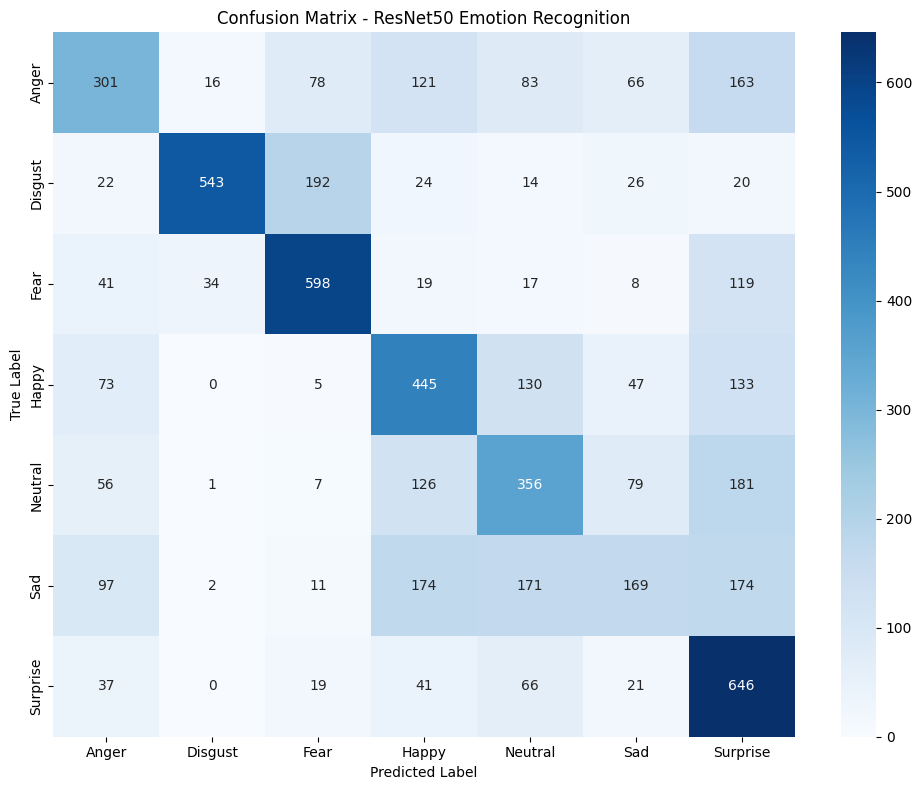

In [ ]:
print("\n" + "="*60)
print("🔮 GENERATING PREDICTIONS")
print("="*60)

# Generate predictions
predictions = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes

# Classification report
print("\n📈 Classification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - ResNet50 Emotion Recognition')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig(os.path.join(DRIVE_MODEL_PATH, 'confusion_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()



📈 PLOTTING TRAINING HISTORY


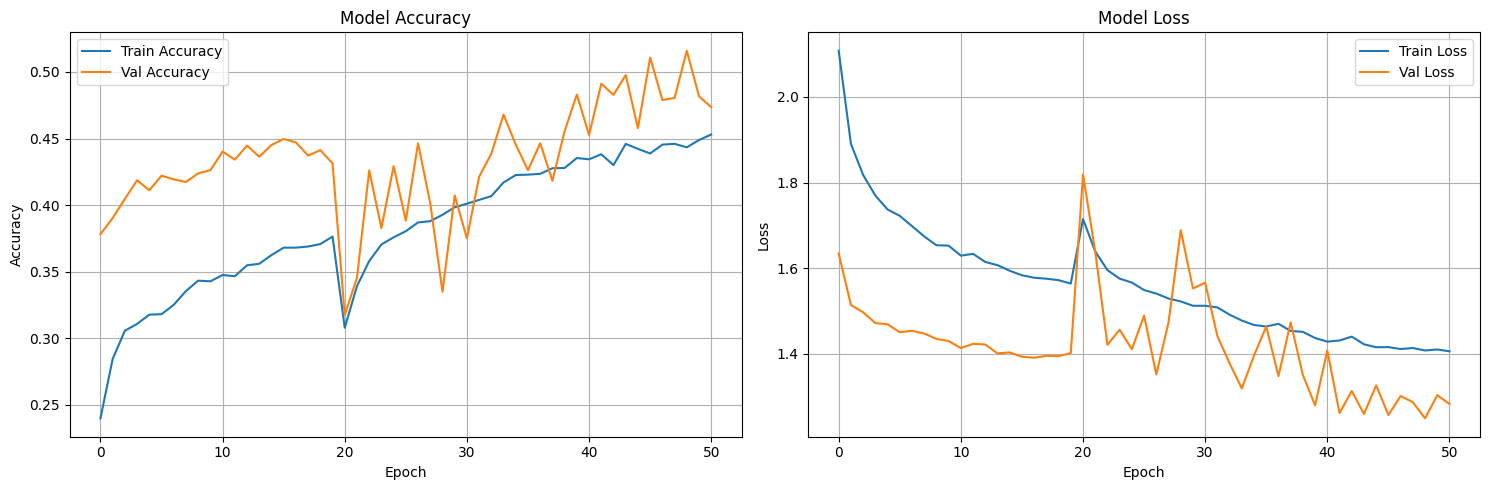


✅ ALL DONE! MODEL TRAINING & EVALUATION COMPLETE


In [ ]:
print("\n" + "="*60)
print("📈 PLOTTING TRAINING HISTORY")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(DRIVE_MODEL_PATH, 'training_history.png'), dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("✅ ALL DONE! MODEL TRAINING & EVALUATION COMPLETE")
print("="*60)